In [2]:
# 라이브러리 호출
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 그래프상에서 한글을 나타내기 위해 korean_mat 설치

import koreanize_matplotlib

%config InlineBackend.figure_format = 'retina'

# 데이터 불러오기
df = pd.read_csv('movie_finished_toFDA_V9.csv')
df.head()

#### 수익성-규모 분석
* 참고 문헌: 개봉 규모와 수익성에 따른 영화의 분류와 확산 패턴 분석


* 규모: 개봉일의 좌석 수를 영화의 규모를 측정하는 대용 척도(proxy measure)로 선정하였다. -> 개봉일의 좌석수를 영화의 규모에 대한 척도로 사용한 이유

* 1. 영화의 제작비가 개봉 이전에 결정되는 요인이라는 점
* 2. 개봉일의 상용관 수 혹은 좌석의 수 경우, 많은 연구에서 영화의 배급력을 나타내는 변수
* 3. 무엇보다 제작자 및 배급사의 입장에서 제작 규모에 따라, 이 두 변수가 제작 규모를 적절히 반영할 것으로 기대할 수 있다.
* 4. 마지막으로, 상영관 수와 좌석 수 모두 영화의 규모를 반영하고 있지만, 멀티플렉스가 대부분인 한국 영화 시장의 특성을 고려할때(전체 상영관 수의 94.5%),규모가 큰 영화일수록 좌석 수가 많은 대형 상영관에 배정된다는 점과 제작비가 높은 3D 영화와 IMAX 영화의 경우 역시 해당 포맷을 위한 상영관이 모두 많은 좌석 수를 가진 점에 주목하였다

In [3]:
# 영화별 개봉일의 좌석수
df_규모_수익성 = pd.DataFrame()
df_규모_수익성['movie_title'] = df['movie_title'].unique()

In [4]:
# 15번째마다 행 남기기
df_규모_수익성 = pd.merge(df[::15][['좌석수', 'movie_title']], df_규모_수익성, on='movie_title', how='left').copy()

* 수익성: 일반적으로, 특정 상품이나 프로젝트 등 투자 대상의 수익성은 투자 규모에 대비한 매출로서 평가된다. 따라서 본 연구에서는 이와 같은 기준으로 사용하여 2주간의 누적 매출를 제작 규모인 개봉일의 좌석수로 나눈 값을 수익성의 척도로 정의하였다.

In [5]:
# 1. 영화별 누적 관객수를 계산
sum_viewer = df.groupby('movie_title')['매출액'].sum()

# 2. 원본 데이터프레임에 누적 관객수를 매핑하여 새로운 컬럼으로 추가
df['누적_매출액'] = df['movie_title'].map(sum_viewer)

In [6]:
df_규모_수익성 = pd.merge(df[['movie_title','누적_매출액']], df_규모_수익성, on='movie_title', how='left').copy()

In [7]:
# 영화별로 묶기
df_규모_수익성 = df_규모_수익성.groupby(['movie_title']).mean()

# 수익성
df_규모_수익성['수익성'] = df_규모_수익성['누적_매출액'] / df_규모_수익성['좌석수']

In [8]:
df_규모_수익성.rename(columns={'좌석수':'규모(좌석수)'}, inplace=True)
df_규모_수익성.drop('누적_매출액', axis=1, inplace=True)
df_규모_수익성

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_63347/3122100250.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_규모_수익성['규모(좌석수)'])


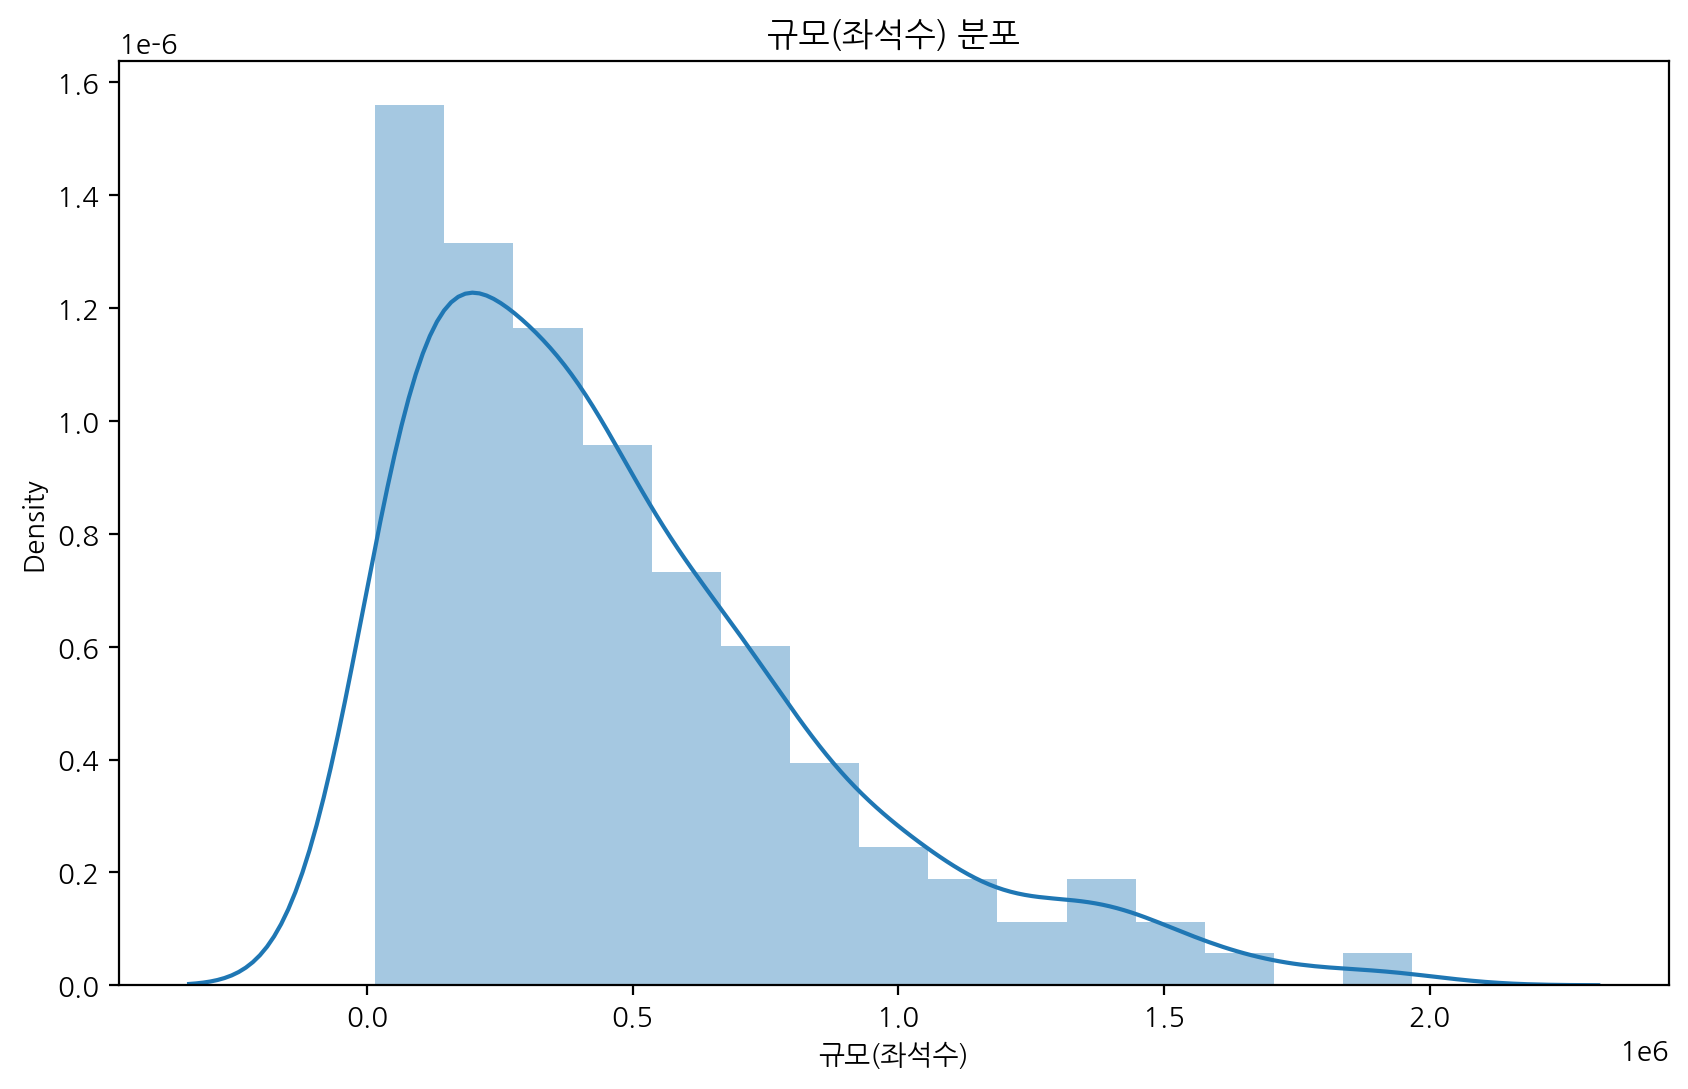

In [9]:
# 규모의 분포
plt.figure(figsize=(10, 6))
sns.distplot(df_규모_수익성['규모(좌석수)'])
plt.title('규모(좌석수) 분포')
plt.show()

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_63347/1484571289.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_규모_수익성['수익성'])


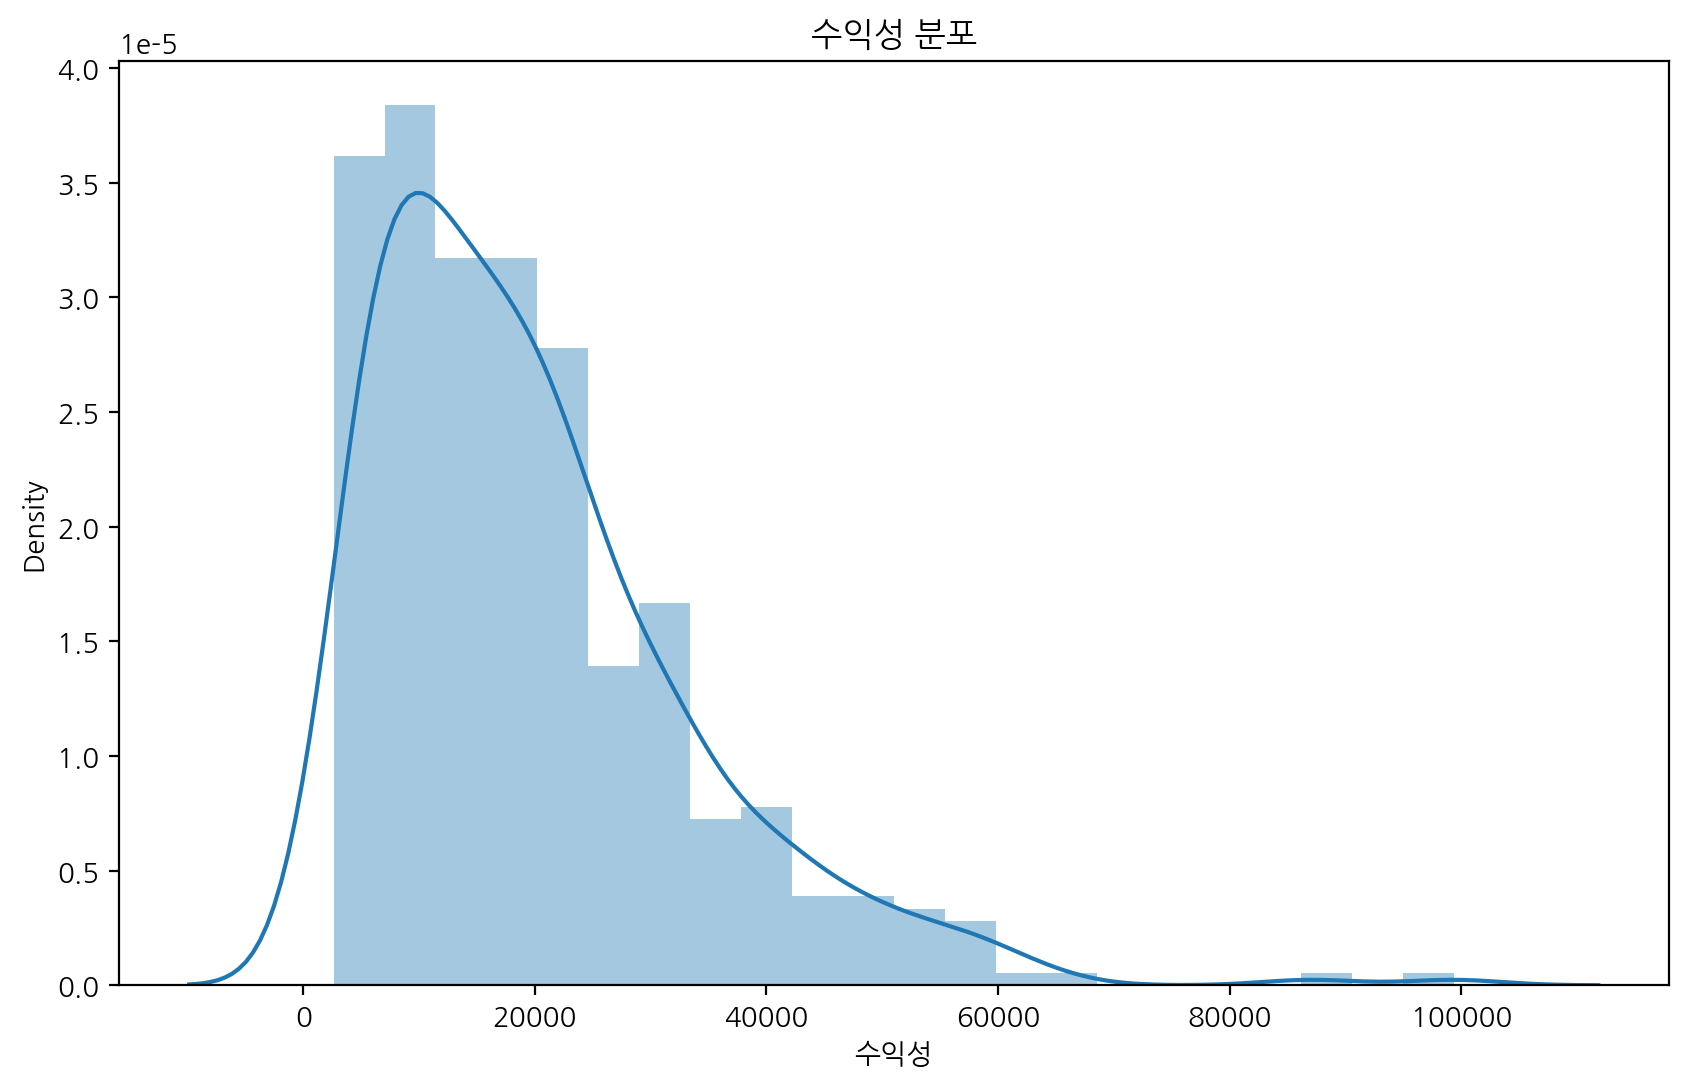

In [10]:
# 수익성의 분포
plt.figure(figsize=(10, 6))
sns.distplot(df_규모_수익성['수익성'])
plt.title('수익성 분포')
plt.show()

#### 1. 두개의 축으로 산점도 그리기

In [11]:
# min-max 정규화
df_규모_수익성['규모(좌석수)'] = (df_규모_수익성['규모(좌석수)'] - df_규모_수익성['규모(좌석수)'].min()) / (df_규모_수익성['규모(좌석수)'].max() - df_규모_수익성['규모(좌석수)'].min())
df_규모_수익성['수익성'] = (df_규모_수익성['수익성'] - df_규모_수익성['수익성'].min()) / (df_규모_수익성['수익성'].max() - df_규모_수익성['수익성'].min())

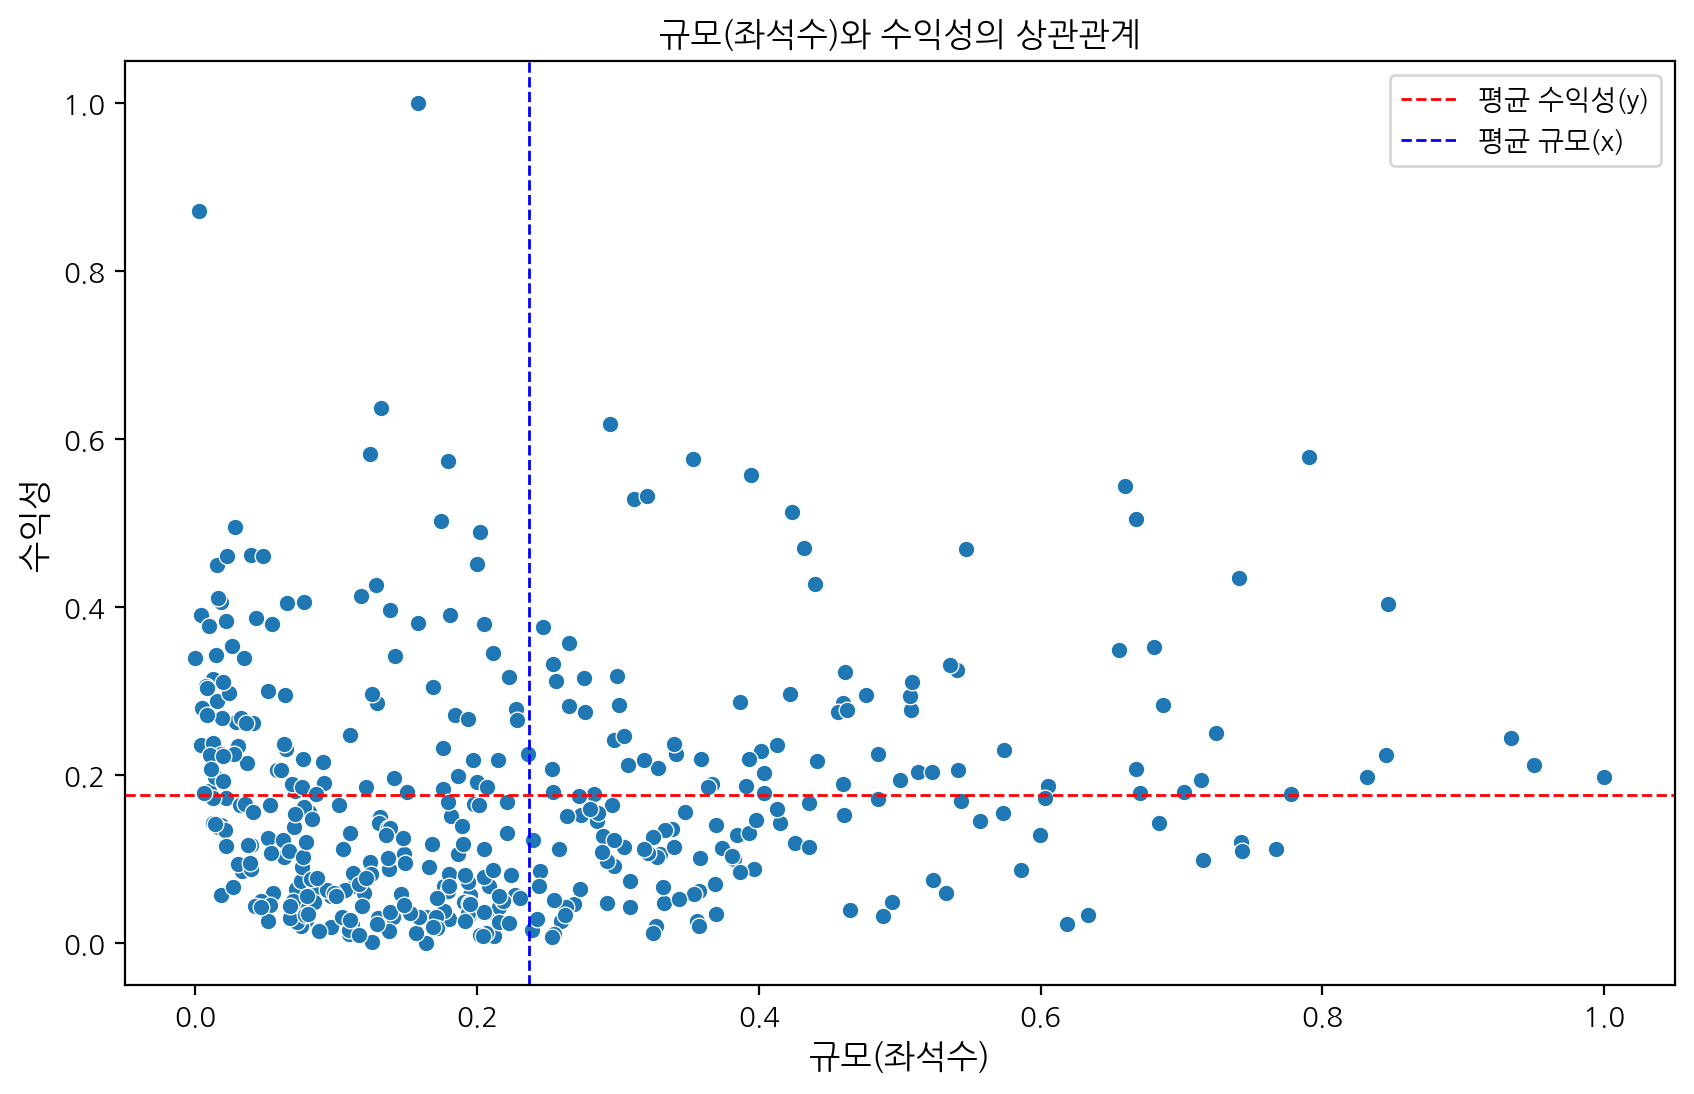

In [15]:
# 규모(좌석수)와 수익성의 상관관계
x_mean = df_규모_수익성['규모(좌석수)'].mean()
y_mean = df_규모_수익성['수익성'].mean()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성')
plt.axhline(y=y_mean, color='red', linestyle='--', linewidth=1, label=f'평균 수익성(y)')
plt.axvline(x=x_mean, color='blue', linestyle='--', linewidth=1, label=f'평균 규모(x)')
plt.title('규모(좌석수)와 수익성의 상관관계')
plt.xlabel('규모(좌석수)', fontsize=12)
plt.ylabel('수익성', fontsize=12)
plt.legend(loc='upper right', fontsize=10)  # 범례 위치와 글자 크기 설정
plt.show()

#### min-max를 통한 정규화를 한 다음 -> k-means_clustering

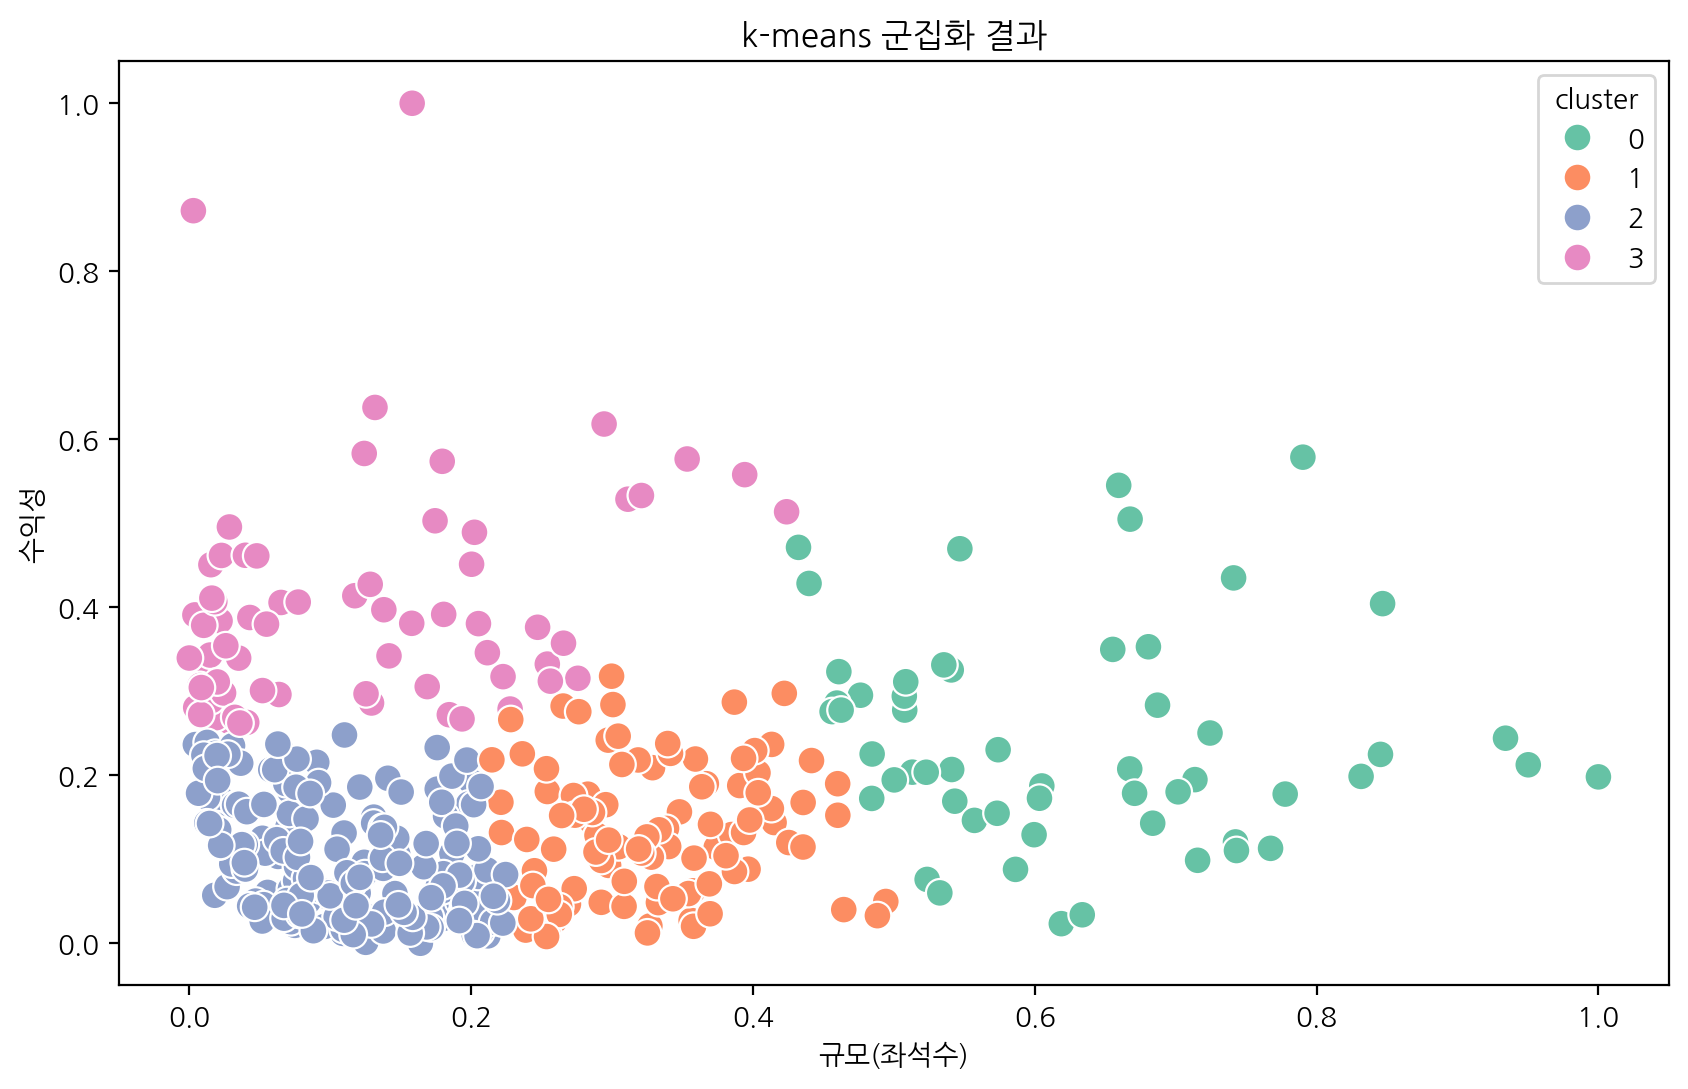

In [16]:
# min-max 정규화
# df_규모_수익성['규모(좌석수)'] = (df_규모_수익성['규모(좌석수)'] - df_규모_수익성['규모(좌석수)'].min()) / (df_규모_수익성['규모(좌석수)'].max() - df_규모_수익성['규모(좌석수)'].min())
# df_규모_수익성['수익성'] = (df_규모_수익성['수익성'] - df_규모_수익성['수익성'].min()) / (df_규모_수익성['수익성'].max() - df_규모_수익성['수익성'].min())

# k-means 군집화
from sklearn.cluster import KMeans

# k-means 모델 생성
kmeans = KMeans(n_clusters=4, random_state=123)

# 모델 학습
kmeans.fit(df_규모_수익성)

# 군집 결과
df_규모_수익성['cluster'] = kmeans.labels_

# 군집 시각화
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성', hue='cluster', palette='Set2', s=100)
plt.title('k-means 군집화 결과')
plt.show()

In [18]:
# 군집별 통계량
df_규모_수익성.groupby('cluster').mean()

# 군집 개수
df_규모_수익성['cluster'].value_counts()

cluster
2    184
1    103
3     67
0     55
Name: count, dtype: int64

* Cluster 0:
    * 규모(좌석수)가 가장 큼 (54.1%).
    * 수익성은 두 번째로 높음 (21.6%).

* Cluster 1:
    * 규모(좌석수)가 중간 크기 (24.8%).
    * 수익성은 가장 낮음 (9.4%).

* Cluster 2:
    * 규모(좌석수)가 두 번째로 작음 (8.2%).
    * 수익성은 Cluster 1보다 높지만 상대적으로 낮음 (9.9%).

* Cluster 3:
    * 규모(좌석수)가 가장 작음 (11.5%).
    * 수익성이 가장 높음 (37.1%).

#### 군집별 회귀 모델을 돌릴 수 있을까? 혹은 군집별 누적 관객수 추이를 볼 수 있을까?

In [52]:
df_규모_수익성_0 = df_규모_수익성[df_규모_수익성['cluster'] == 0]
df_규모_수익성_1 = df_규모_수익성[df_규모_수익성['cluster'] == 1]
df_규모_수익성_2 = df_규모_수익성[df_규모_수익성['cluster'] == 2]
df_규모_수익성_3 = df_규모_수익성[df_규모_수익성['cluster'] == 3]

In [53]:
df_규모_수익성_0

In [54]:
df_규모_수익성_1

In [55]:
df_규모_수익성_2

In [56]:
df_규모_수익성_3

#### 가설 검증
* 1. 군집별 매출액? 수익성?은 영화의 내적 특성에 영향을 받는다.
* 2. 군집별 매출액? 수익성?은 스크린수에 영향을 받는다.
* 3. 군집별 매출액? 수익성?은 구전효과에 영향을 받는다.

 #### 각각의 군집은 확산 패턴 측면에서 다음과 같은 몇 가지 차이를 보여주었다. 
 * 첫 번째로, 입소문 효과를 의미하는 확산 계수의 비율은 수익성이 높은 군집들에서 높게 나타난다. 이는 영화의 수익성이 입소문 효과와 밀접한 관련이 있다는 것을 의미하며, 특히 중규모-고수익성 군집에서 가장 높고 중규모 두 군집간의 차이가 대규모에서보다 크다는 사실은 매스 미디어 노출이 관객과의 주요 통로가 되는 대규모 영화에 비해 중규모 영화에 있어서 입소문 효과의중요성이 더욱 크다는 것을 나타낸다. 

 * 또한, 수익성이 낮은 영화들의 일별 박스오피스 확산 패턴 상 최대 시점과 포화 시점및 두 시점 간의 간격이 짧다는 것은 수익성이 낮은 영화들의짧은 상영 기간을 설명해 주고 있다. 
 
 * 마지막으로, 확장 Bass 모형 상의 특성인 초기 수요가 수익성이 낮은 영화들에서 높게나타난다는 사실과 더불어, 정규화된 확산 패턴에서 수익성이낮은 영화들이 최대 시점에 빠르게 도달한다는 결과들은 수익성 낮은 영화들이 개봉 초기의 수익 수준에서 단조로운 감소형태로 전환되는 확산 패턴을 가지고 있음을 의미한다.이러한 결과는 영화 산업에 관련해서 다음과 같은 시사점을제시하고 있다. 개봉 규모와 수익성의 상관관계가 높지 않으며, 군집 간 수익성의 편차가 크다는 점에서 스크린 배분을 통한 개봉 전략이 영화의 성공을 결정하는 절대적인 요인이 아니라는 사실을 알 수 있다. 실제로, 수익성이 높은 영화들의 분석 결과상의 두드러지는 특징은, 입소문 효과 등으로 인해 유발된 개봉 후 증가추세를 동반한 상영 기간의 증가이다. 따라서 초기에 과도한 스크린 확보에 집중하는 와이드 릴리즈(wide-release, 광역 개봉) 일변도의 전략 보다는, 다양한 대안을 고려하는 것이 필요하다. 특히, 중소 규모 영화에 대해서는입소문 효과가 크게 작용한다는 점을 고려하여, 이를 활용할수 있는 마케팅 전략과 롤 아웃(limited roll-out) 방식의 개봉 전략의 유용성에 주목하여야 할 것이다.